# Week 11 — Ultrasound M-mode (a scan line over time)

A preview of ultrasound imaging, motivated by the echocardiography project (stacking video frames into
a 3-D volume). Standard **B-mode** ultrasound is a 2-D image that updates in time (a video).
**M-mode** (“motion mode”) instead takes a **single scan line** and plots it **over time** — depth on
one axis, time on the other — giving very high temporal resolution for moving structures (heart
valves, vessel walls, chamber walls).

**The key insight for the 3-D-video projects:** if you stack the video frames into a volume
`(time, depth, width)`, then an **M-mode image is just a slice through that volume along the time
axis**. This notebook simulates a beating wall, builds its M-mode, and recovers the **heart rate**.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)
plt.rcParams["figure.dpi"] = 110

# Simulate a B-mode video: a bright wall echo that oscillates (a beating heart / pulsating vessel)
H, W, T = 120, 120, 360        # depth, width, frames
fps = 30.0                     # frames per second
hr_true = 72.0                 # beats per minute
freq = hr_true / 60.0          # Hz
depth = np.arange(H)[:, None]

frames = np.empty((T, H, W))
for t in range(T):
    wall = 60 + 18 * np.sin(2 * np.pi * freq * t / fps)      # wall depth oscillates
    echo = np.exp(-((depth - wall) ** 2) / (2 * 4 ** 2))     # bright echo band
    frames[t] = np.tile(echo, (1, W)) + 0.05 * rng.standard_normal((H, W))
print(f"B-mode video: {frames.shape} (time, depth, width) at {fps:g} fps")

B-mode video: (360, 120, 120) (time, depth, width) at 30 fps


## 1. A B-mode frame and the chosen M-line

In B-mode we see one frame at a time. To build an M-mode we pick a **single vertical scan line**
(fixed lateral position) — the dashed line below — and watch only that line as the structure moves.

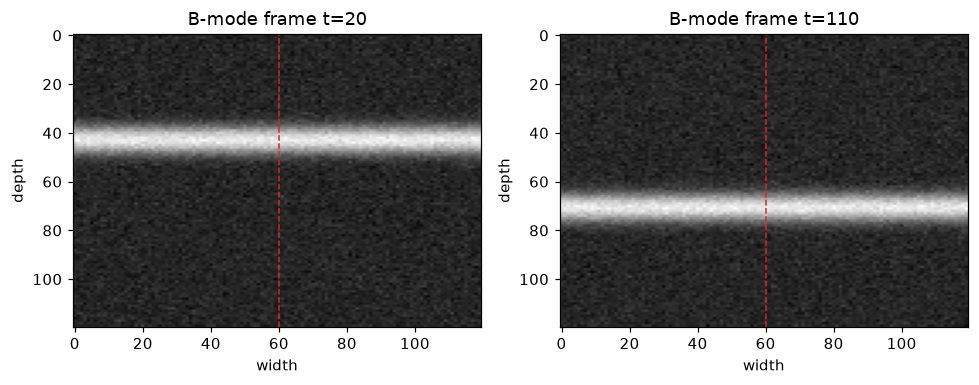

In [2]:
x0 = W // 2                                     # the M-line (lateral position)
fig, ax = plt.subplots(1, 2, figsize=(9, 3.6))
for a, t in zip(ax, [20, 110]):
    a.imshow(frames[t], cmap="gray", aspect="auto")
    a.axvline(x0, color="tab:red", ls="--", lw=1)
    a.set_title(f"B-mode frame t={t}"); a.set_xlabel("width"); a.set_ylabel("depth")
plt.tight_layout(); plt.show()

## 2. M-mode = stack that line over time

Taking column `x0` from every frame and placing the columns **side by side in time** gives the M-mode
image: **depth (vertical) vs time (horizontal)**. The moving wall traces the characteristic sinusoidal
band — the same picture a cardiologist reads for valve/wall motion. This is exactly a **time-axis
slice** of the stacked video volume.

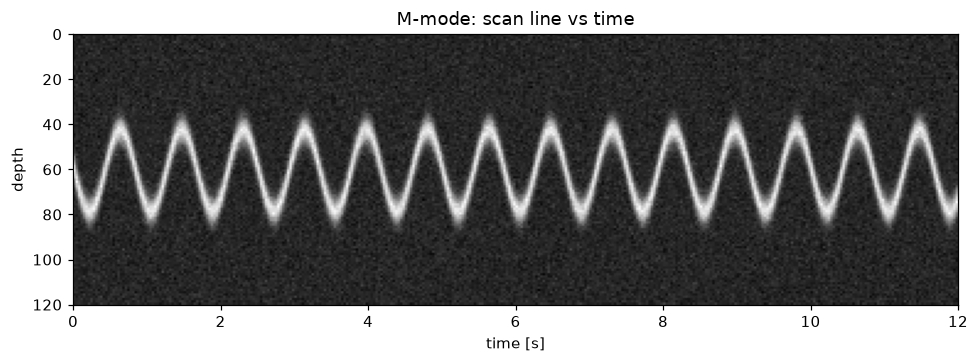

In [3]:
mmode = frames[:, :, x0].T                      # (depth, time) = a slice of the (t, depth, w) volume

plt.figure(figsize=(9, 3.4))
plt.imshow(mmode, cmap="gray", aspect="auto", extent=(0, T / fps, H, 0))
plt.xlabel("time [s]"); plt.ylabel("depth"); plt.title("M-mode: scan line vs time")
plt.tight_layout(); plt.show()

## 3. Measure motion: heart rate from the M-mode

Tracking the brightest depth at each time gives the wall-motion trace; its dominant **frequency**
(from an FFT) is the **heart rate**. M-mode's high temporal sampling is what makes such timing
measurements precise.

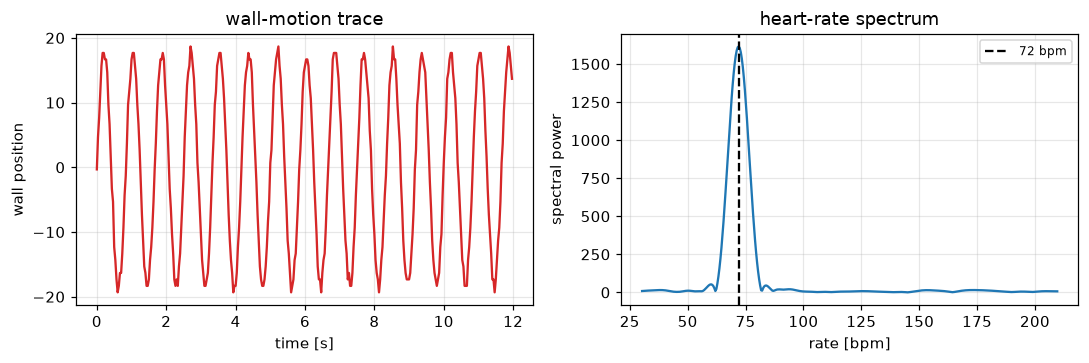

estimated heart rate = 72.1 bpm (true 72)


In [4]:
trace = mmode.argmax(axis=0).astype(float)      # wall depth vs time
trace -= trace.mean()

n = 4096                                         # zero-pad for fine frequency resolution
spec = np.abs(np.fft.rfft(trace * np.hanning(T), n))
freqs = np.fft.rfftfreq(n, d=1 / fps)
band = (freqs > 0.5) & (freqs < 3.5)            # 30-210 bpm
hr_est = freqs[band][spec[band].argmax()] * 60

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(np.arange(T) / fps, trace, color="tab:red")
ax[0].set_xlabel("time [s]"); ax[0].set_ylabel("wall position"); ax[0].set_title("wall-motion trace"); ax[0].grid(alpha=0.3)
ax[1].plot(freqs[band] * 60, spec[band], color="tab:blue")
ax[1].axvline(hr_est, color="k", ls="--", label=f"{hr_est:.0f} bpm")
ax[1].set_xlabel("rate [bpm]"); ax[1].set_ylabel("spectral power"); ax[1].set_title("heart-rate spectrum")
ax[1].legend(fontsize=8); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(f"estimated heart rate = {hr_est:.1f} bpm (true {hr_true:.0f})")

## Takeaways

- **B-mode** = a 2-D image over time (video); **M-mode** = one **scan line** over time (depth vs time),
  trading spatial coverage for **high temporal resolution**.
- M-mode makes **motion timing** easy — valve opening, wall excursion, **heart rate** — here recovered
  to within ~0.1 bpm by FFT.
- For the echo “stack frames into a volume” projects, **M-mode is a time-axis slice** of that
  `(time, depth, width)` volume — a free extra view alongside the 3-D structure.
- Full ultrasound physics (pressure waves, acoustic impedance, the swept beam and point-spread) comes
  in the ultrasound module; this is the motion-analysis preview.